In [2]:
!mamba install pandas numpy matplotlib seaborn openpyxl

mambajs 0.21.4

Specs: xeus-python, numpy, matplotlib, pillow, ipywidgets>=8.1.6, ipyleaflet, scipy, pandas, seaborn, openpyxl
Channels: emscripten-forge-4x, conda-forge

Solving environment...
Solving took 3.629 seconds
  Name           Version  Build                Channel
--------------------------------------------------------------------
+ et_xmlfile     2.0.0    pyhd8ed1ab_1         conda-forge
+ openpyxl       3.0.9    pyhd8ed1ab_0         conda-forge
+ pandas         3.0.6    np23py313h124dbc7_0  emscripten-forge-4x
+ patsy          1.0.3    py313h1804a44_0      emscripten-forge-4x
+ python-tzdata  2026.5   pyh5ded981_0         conda-forge
+ seaborn        0.13.2   hd8ed1ab_3           conda-forge
+ seaborn-base   0.13.2   pyhd8ed1ab_3         conda-forge
+ statsmodels    0.14.6   np23py313hd8db738_2  emscripten-forge-4x
- pip            26.2.1   pyh145f28c_0         conda-forge


         Date    Product  Sales  Quantity Region
0  01-01-2023  Product A    200         4  North
1  02-01-2023  Product B    150         3  South
2  03-01-2023  Product A    220         5  North
3  04-01-2023  Product C    300         6   East
4  05-01-2023  Product B    180         4   West
Date        0
Product     0
Sales       0
Quantity    0
Region      0
dtype: int64
            Sales   Quantity
count   16.000000  16.000000
mean   237.500000   5.375000
std     64.031242   1.746425
min    150.000000   3.000000
25%    187.500000   4.000000
50%    225.000000   5.500000
75%    302.500000   7.000000
max    340.000000   8.000000
     Product  Sales  Quantity
0  Product A   1350        33
1  Product B    850        17
2  Product C   1600        36


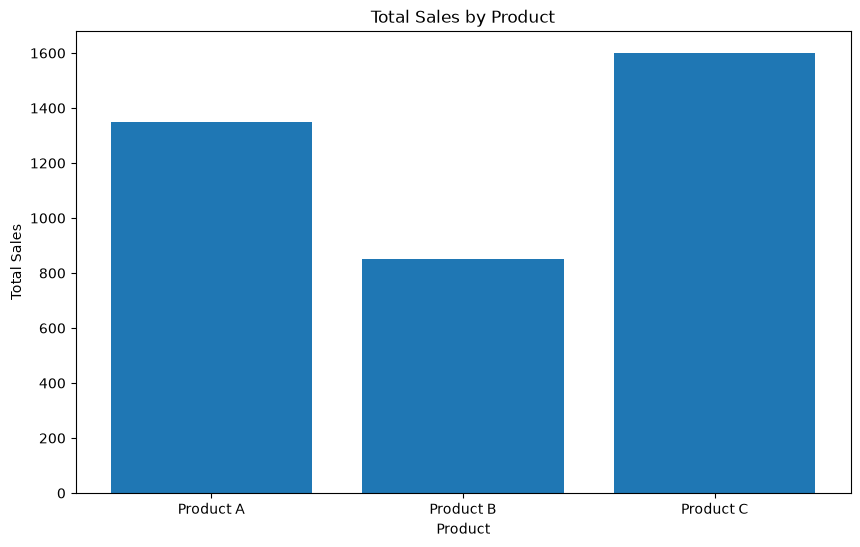

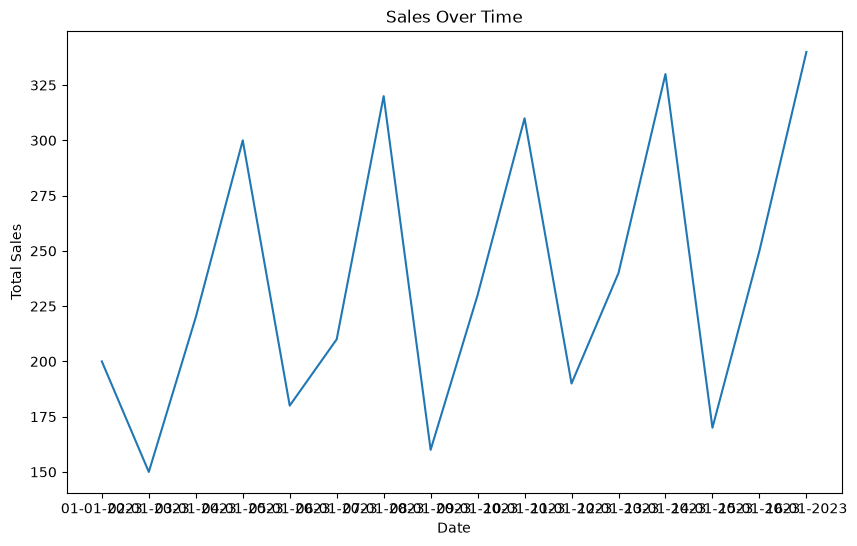

Product  Product A  Product B  Product C
Region                                  
East             0          0       1600
North         1350          0          0
South            0        480          0
West             0        370          0
             Sales  Quantity
Sales     1.000000  0.944922
Quantity  0.944922  1.000000


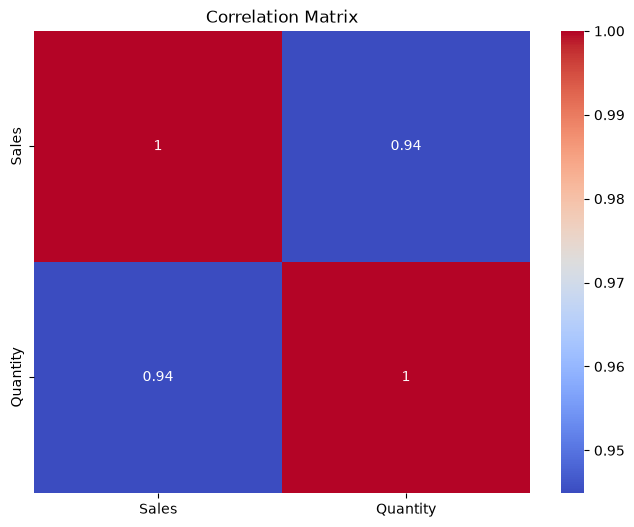

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

file_path = r'sales_data.csv'
df = pd.read_csv(file_path, parse_dates=['Date'])

print(df.head())
print(df.isnull().sum())

df['Sales'] = df['Sales'].fillna(df['Sales'].mean())
df = df.dropna(subset=['Product', 'Quantity', 'Region'])

print(df.describe())

product_summary = df.groupby('Product').agg({
    'Sales': 'sum',
    'Quantity': 'sum'
}).reset_index()
print(product_summary)

# Bar plot
plt.figure(figsize=(10, 6))
plt.bar(product_summary['Product'], product_summary['Sales'])
plt.xlabel('Product')
plt.ylabel('Total Sales')
plt.title('Total Sales by Product')
plt.show()

# Line plot
sales_over_time = df.groupby('Date').agg({'Sales': 'sum'}).reset_index()
plt.figure(figsize=(10, 6))
plt.plot(sales_over_time['Date'], sales_over_time['Sales'])
plt.xlabel('Date')
plt.ylabel('Total Sales')
plt.title('Sales Over Time')
plt.show()

# Pivot table
pivot_table = df.pivot_table(values='Sales', index='Region',
                             columns='Product', aggfunc='sum', fill_value=0)
print(pivot_table)

# Correlation
correlation_matrix = df.corr(numeric_only=True)
print(correlation_matrix)

plt.figure(figsize=(8, 6))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm')
plt.title('Correlation Matrix')
plt.show()